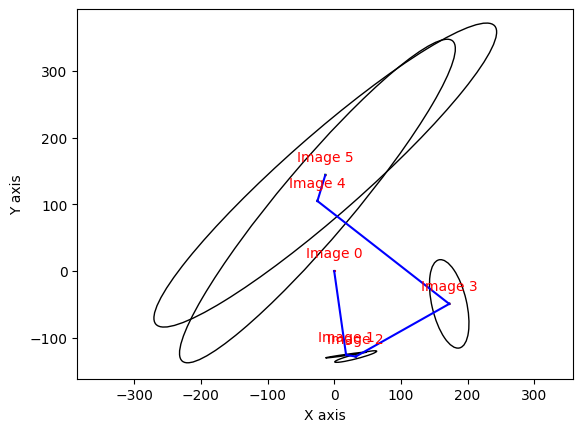

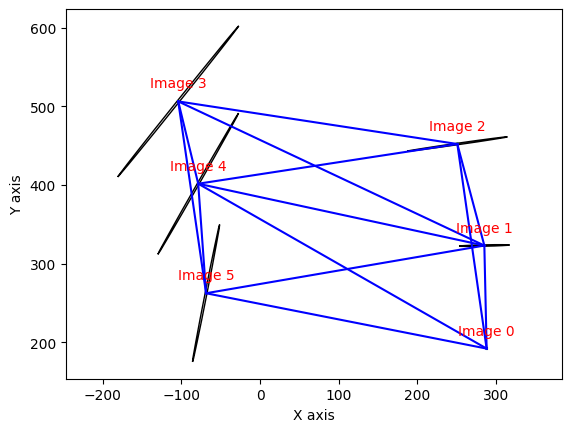

X1 covariance:
[[ 1.71089499e+02 -1.13620734e+01 -1.30750494e+00]
 [-1.13620734e+01  8.80359272e-01  8.69962270e-02]
 [-1.30750494e+00  8.69962270e-02  1.00024883e-02]]

X2 covariance:
[[ 6.78720964e+02  8.92252755e+01 -2.60506180e+00]
 [ 8.92252755e+01  1.18809694e+01 -3.42407647e-01]
 [-2.60506180e+00 -3.42407647e-01  1.00053368e-02]]

X3 covariance:
[[ 1.33443648e+03  1.26026404e+03 -3.65406706e+00]
 [ 1.26026404e+03  1.19075626e+03 -3.45076713e+00]
 [-3.65406706e+00 -3.45076713e+00  1.00102310e-02]]

X4 covariance:
[[ 4.09178738e+02  7.49807709e+02 -2.02299689e+00]
 [ 7.49807709e+02  1.37493824e+03 -3.70806777e+00]
 [-2.02299689e+00 -3.70806777e+00  1.00124142e-02]]

X5 covariance:
[[ 7.77048215e+01  3.10475324e+02 -8.79695978e-01]
 [ 3.10475324e+02  1.24442369e+03 -3.52759864e+00]
 [-8.79695978e-01 -3.52759864e+00  1.43179370e-02]]



In [1]:
import gtsam
import numpy as np
import math
import glob
import os
import itertools
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import gtsam.utils.plot as gtsam_plot
import cv2


def load_images(images_folder_path):
    
    images = []
    images_paths_list = sorted(filter(os.path.isfile, glob.glob(images_folder_path + '*')))

    for image_path in images_paths_list:
        images.append(cv2.imread(image_path))

    return images

def convert_to_grayscale(images):
    
    gray_images = [cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) for image in images]

    return gray_images

def normalize_images(gray_images):
    
    normalized_gray_images = []
    
    for image in gray_images:
        
        normalized_gray_image = cv2.normalize(image, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
        normalized_gray_images.append(normalized_gray_image)

    return normalized_gray_images

def apply_clahe(images_list):

        clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))       
        clahe_gray_images = [clahe.apply(image) for image in images_list]

        return clahe_gray_images

def detect_features(normalized_gray_images):
    sift = cv2.SIFT_create(nfeatures=4000, nOctaveLayers=12, contrastThreshold=0.025, sigma=1.5)
    kp_list = []
    des_list = []
    out_images = []
    for image in normalized_gray_images:
        kp, des = sift.detectAndCompute(image, None)
        out_image = cv2.drawKeypoints(image, kp, image, color=[255, 255, 0], flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        kp_list.append(np.array(kp))
        des_list.append(np.array(des))
        out_images.append(out_image)

    return kp_list, des_list, out_images

def match_and_filter(matcher, des1, des2, threshold=0.90, dist_mask_12=None, draw_plot_dist=False):
        
        if dist_mask_12 is None:
            dist_mask_21 = None
        else:
            dist_mask_21 = dist_mask_12.T
        matches_knn = matcher.knnMatch(des2, des1, k=2, mask=dist_mask_21)
        all_ds = [m[0].distance for m in matches_knn if len(m) > 0]

        matches = []

        mask = np.zeros((des1.shape[0], des2.shape[0]), dtype='uint8')
        for match in matches_knn:
            if len(match) == 1 or (len(match) > 1 and match[0].distance < threshold * match[1].distance):

                matches.append(match[0])
                mask[match[0].trainIdx, match[0].queryIdx] = 1

        if draw_plot_dist:
            fig, axes = plt.subplots(1, 1, num=3)
            filt_ds = [m.distance for m in matches]
            axes.plot(sorted(all_ds), '.', label='All Matches')
            axes.plot(sorted(filt_ds), '.', label='Filtered Matches')
            axes.set_xlabel('Number')
            axes.set_ylabel('Distance')
            axes.legend()
            plt.pause(.1)
        
        matches_cross = matcher.match(des1, des2, mask=mask)

        return matches_cross

def get_matches(kp_list, des_list, only_image_pair=False):

    matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
    matches = []

    kp_match = []
    if only_image_pair:
        matches.append(match_and_filter(matcher, des_list[0], des_list[1], threshold=0.90))
        kp0_match_pts = np.array([kp_list[0][mat.queryIdx].pt for mat in matches[0]])
        kp1_match_pts = np.array([kp_list[1][mat.trainIdx].pt for mat in matches[0]])
        kp_match.append((kp0_match_pts, kp1_match_pts))
    else:

        for i in range(6):
            if i < 5:
                matches.append(match_and_filter(matcher, des_list[i], des_list[i + 1], threshold=0.90))
                kp0_match_pts = np.array([kp_list[i][mat.queryIdx].pt for mat in matches[i]])
                kp1_match_pts = np.array([kp_list[i + 1][mat.trainIdx].pt for mat in matches[i]])
            else:
  
                matches.append(match_and_filter(matcher, des_list[i], des_list[0], threshold=0.90))
                kp0_match_pts = np.array([kp_list[i][mat.queryIdx].pt for mat in matches[i]])
                kp1_match_pts = np.array([kp_list[0][mat.trainIdx].pt for mat in matches[i]])

            kp_match.append((kp0_match_pts, kp1_match_pts))
    return matches, kp_match

def get_inliers(kp_list, matches, kp_match):

    mask_e = []
    kp_match_inliers = []
    i = 0
    for k_match in kp_match:
        F, maskMatch = cv2.findFundamentalMat(k_match[0], k_match[1],
                                                method=cv2.FM_RANSAC,
                                                ransacReprojThreshold=1.0,
                                                confidence=0.9999)
        mask_e.append(maskMatch)

        kp0_match_inliers = [kp_list[i][mat.queryIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]
        if i < 5:
            kp1_match_inliers = [kp_list[i + 1][mat.trainIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]
        else:
            kp1_match_inliers = [kp_list[0][mat.trainIdx] for mat, msk in zip(matches[i], mask_e[i]) if msk]

        kp_match_inliers.append((kp0_match_inliers, kp1_match_inliers))
        i += 1

    return kp_match_inliers, mask_e

def homography_calculation(kp_match_inliers, inliers=True):
    h = []
    pts_left_src = []
    pts_right_dst = []
    mask = []
    
    if inliers:
        for kp_match in kp_match_inliers:
            pts_left_src.append(np.float32([kp_match[0][i].pt for i in range(len(kp_match[0]))]))
            pts_right_dst.append(np.float32([kp_match[1][i].pt for i in range(len(kp_match[1]))]))
    else:
        for kp_match in kp_match_inliers:
            pts_left_src.append(np.float32([kp_match[0][i] for i in range(len(kp_match[0]))]))
            pts_right_dst.append(np.float32([kp_match[1][i] for i in range(len(kp_match[1]))]))
    
    for i in range(len(pts_left_src)):
        if inliers:
            h_img, mask_img = cv2.findHomography(pts_right_dst[i], pts_left_src[i])
        else:
            h_img, mask_img = cv2.findHomography(pts_right_dst[i], pts_left_src[i], cv2.RANSAC, 1.0)
        h.append(h_img)
        mask.append(mask_img)
    
    return h, mask, pts_left_src, pts_right_dst

def is_homography_good(h):
    hR = h[0:2,0:2]
    if np.linalg.det(hR) > 0:
        return True
    else:
        return False


def odometry_noise(mask):

    numMatches = np.count_nonzero(mask)

    minError = [0.2, 0.2, 0.1]
    smallError = [0.5, 0.5, 0.25]
    largeError = [0.8, 0.8, 0.4]
    maxError = [1.0, 1.0, 0.5]
    
    if numMatches > 100:
        err = minError
    elif numMatches > 50 and numMatches <= 100:
        err = smallError
    elif numMatches > 20 and numMatches <= 50:
        err = largeError
    else:

        err = maxError
    
    return gtsam.noiseModel.Diagonal.Sigmas(gtsam.Point3(err[0], err[1], err[2]))

def get_factor_pose(index, pts_src, pts_dst):
    global ransac_mask

    similarity_mat, ransac_mask = cv2.estimateAffinePartial2D(pts_dst[index], pts_src[index])

    scale = np.sqrt(similarity_mat[0, 0]**2 + similarity_mat[1, 0]**2)

    similarity_mat[:2, :2] /= scale

    affine_matrix = np.vstack((similarity_mat, [0, 0, 1]))

    pose = gtsam.Pose2(affine_matrix[0, -1], affine_matrix[1, -1],
                       np.arctan2(affine_matrix[1, 0], affine_matrix[0, 0]))

    return pose

def extract_homography_pose(h):

    affineEst = h.copy()

    affineEst[2][0] = 0
    affineEst[2][1] = 0

    scale = np.sqrt(affineEst[0, 0]**2 + affineEst[1, 0]**2)

    affineEst[:2, :2] /= scale

    total_affine_matrix = np.eye(3)

    affineEst_inv = np.linalg.inv(affineEst)
    affineEst = affineEst_inv.dot(total_affine_matrix)

    pose = gtsam.Pose2(affineEst[0, -1], affineEst[1, -1],
                       np.arctan2(affineEst[1, 0], affineEst[0, 0]))

    return pose

def initial_estimates(h):

    initial_estimate = gtsam.Values()
    initial_estimate.insert(0, gtsam.Pose2())

    for i in range(len(h) - 1):

        initial_estimate.insert(i+1, extract_homography_pose(h[i]))

    return initial_estimate

def plot_graph(initial, graph, marginals):

    image_numbers = {}

    for node in range(initial.size()):

        pose = initial.atPose2(node)
        gtsam_plot.plot_pose2(0, pose, 0.5, marginals.marginalCovariance(node))

        plt.annotate(f"Image {node}", (pose.x(), pose.y()), textcoords="offset points", xytext=(0, 10),
                     ha='center', fontsize=10, color='red')

        image_numbers[node] = pose

    for edge in range(graph.size())[1:]:
    
        start_key, end_key = graph.at(edge).keys()

        start_pose = image_numbers[start_key]
        end_pose = image_numbers[end_key]

        plt.plot([start_pose.x(), end_pose.x()], [start_pose.y(), end_pose.y()], color='blue')

    plt.axis('equal')
    plt.show()

if __name__ == "__main__":

    images_folder_path = "6Images/"
    images = load_images(images_folder_path)
    
    gray_images = convert_to_grayscale(images)
    normalized_gray_images = normalize_images(gray_images)

    image_height, image_width = normalized_gray_images[0].shape

    clahe_normalized_gray_images = apply_clahe(normalized_gray_images)

    kp_list, des_list, outImages = detect_features(normalized_gray_images)

    matches, kp_match = get_matches(kp_list, des_list)

    kp_match_inliers, inlier_mask = get_inliers(kp_list, matches, kp_match)

    h, mask, pts_left_src, pts_right_dst = homography_calculation(kp_match, inliers=False)

    PRIOR_NOISE = gtsam.noiseModel.Diagonal.Sigmas(gtsam.Point3(0.3, 0.3, 0.1))
    graph = gtsam.NonlinearFactorGraph()

    graph.add(gtsam.PriorFactorPose2(0, gtsam.Pose2(image_width/2, image_height/2, 0), PRIOR_NOISE))

    get_factor_pose(0, pts_right_dst, pts_right_dst)

    initial = initial_estimates(h)

    for src, dst in itertools.combinations(range(len(normalized_gray_images)), 2):

        if src + 1 == dst:

            pose_transformation = get_factor_pose(src, pts_left_src, pts_right_dst)
            
            noise_model = odometry_noise(mask[src])
            
            factor = gtsam.BetweenFactorPose2(src, dst, pose_transformation, noise_model)
            
            graph.add(factor)
    marginals = gtsam.Marginals(graph, initial)
    plot_graph(initial, graph, marginals)


for src, dst in itertools.combinations(range(len(normalized_gray_images)), 2):
    if src + 1 != dst:

        match_overlap, kp_match_overlap = get_matches([kp_list[src],kp_list[dst]], [des_list[src],des_list[dst]], only_image_pair=True)
        homography, _, _, _= homography_calculation(kp_match_overlap, inliers = False)

        if homography is not None and is_homography_good(homography[0]):

            pts_left_overlap  = []
            pts_right_overlap = []
            for kp_matches in kp_match_overlap:
                pts_left_overlap.append(np.float32([kp_matches[0][i] for i in range(len(kp_matches[0]))]))
                pts_right_overlap.append(np.float32([kp_matches[1][i] for i in range(len(kp_matches[1]))]))

            factor_pose = get_factor_pose(0, pts_left_overlap, pts_right_overlap)
            if factor_pose is not None:
                graph.add(gtsam.BetweenFactorPose2(src, dst,
                                    factor_pose, odometry_noise(ransac_mask)))
                
params = gtsam.LevenbergMarquardtParams()
optimizer = gtsam.LevenbergMarquardtOptimizer(graph, initial, params)
initial = optimizer.optimize()
marginals = gtsam.Marginals(graph, initial)
plot_graph(initial, graph, marginals)

marginals = gtsam.Marginals(graph, initial)
for i in range(1, 6):
    print("X{} covariance:\n{}\n".format(i, marginals.marginalCovariance(i)))